# 3장 2강 · 모델 오류 분석과 성능 개선

**실습문제**

작은 동물을 놓치는 모델의 입력을 키우면 같은 사진에서 무엇이 달라질까요? 가중치를 먼저 실제로 학습한 뒤, 두 입력 크기를 같은 원본에 적용합니다. 전체 정답 수가 바뀐 이유를 개별 객체 번호까지 거슬러 올라가 확인합니다.

| 구분 | 수행할 일 |
|---|---|
| 필수 1 | 학습 기록 확인 → 예측과 정답 연결 → 오류 유형별 집계 → 작은 객체에 관한 가설 작성 |
| 필수 2 | 자르기·반전에서 객체 라벨 점검 → 같은 모델의 입력 크기 변경 → 회복·악화 사례 검토 |
| 독립 과제 | 다른 사진의 자르기 검수 → 공정한 전후 평가와 설정 선택 → 처음 보는 사진으로 최종 검증 |

**실행 준비**　기존 `coco_sample.zip` 또는 `coco_dataset.zip`을 노트북과 같은 폴더에 둡니다. Python 3.10 이상, Jupyter, 호환되는 PyTorch·torchvision, pandas, NumPy, Pillow가 필요합니다. 제작 시 CPU에서 torch 2.6.0, torchvision 0.21.0으로 실행했습니다. 첫 사용 시 COCO 사전학습 Mask R-CNN 가중치 약 170 MB를 내려받고 이후 캐시에서 읽습니다. 정답 노트북에는 측정한 출력과 그림이 저장돼 있습니다.

**실험 설계**　제공된 COCO val2017 표본에서 사진 ID 기준으로 Train 12장, Validation 14장, Test 12장을 나눕니다. 평가 대상은 얼룩말·고양이·개이고, 학습 시에는 선택한 사진의 모든 개별 객체 주석을 사용합니다. Train에서 출력층을 한 번 미세조정하고, 그 가중치를 두 평가 설정이 공유합니다. 바꾸는 것은 추론 시 짧은 변의 목표 길이(320 또는 640)입니다. 긴 변 상한은 모두 960입니다. 점수 0.50 이상, 같은 클래스, 박스 IoU 0.50 이상을 정답 검출의 조건으로 사용합니다. 예측 마스크는 픽셀 확률 0.50에서 이진화합니다.

**설정 선택 규칙**　목표는 미검출 감소입니다. Validation에서 Recall이 엄격히 오르고 Precision 하락이 **5%p 이내**이면 640을 선택합니다. 나머지 경우에는 320을 유지합니다. Test는 이 결정을 내린 다음에 엽니다. 선택 규칙과 관심 클래스는 평가 전에 정한 수업용 조건입니다.

공통 준비 셀을 모두 실행한 뒤 각 절을 진행하세요. 독립 과제는 필수 1·2의 답안 변수 없이도 실행할 수 있습니다. 준비 셀은 모델 학습까지 제공합니다. 수강생은 문항에서 판정·집계·결정 근거를 직접 작성합니다.

### 공통 준비 · 사진·주석 읽기

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import pandas as pd
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

data_path = Path("C:/Users/jihun/OneDrive/Desktop/DS 실습자료/LV2/이미지 분석/DATA/2장3강,3장2강,5장/COCO/coco_dataset/coco_dataset.zip")
if not data_path.is_file():
    data_path = Path("coco_dataset.zip")
if not data_path.is_file():
    raise FileNotFoundError("노트북 옆에 coco_sample.zip 또는 coco_dataset.zip을 두세요.")
archive = ZipFile(data_path)
objects = pd.read_csv(archive.open("objects.csv"))
files = set(archive.namelist())
usable = objects.loc[objects.image_path.isin(files) & objects.mask_path.isin(files)]

def read_instance(annotation_id):
    row = usable.loc[usable.annotation_id == annotation_id].iloc[0]
    with Image.open(BytesIO(archive.read(row.image_path))) as src:
        photo = np.asarray(src.convert("RGB")).copy()
    with Image.open(BytesIO(archive.read(row.mask_path))) as src:
        mask = np.asarray(src.convert("L")) == 255
    assert photo.shape[:2] == mask.shape
    return photo, mask

def show_pair(photo, mask):
    # 왼쪽은 사진, 오른쪽은 대상 객체를 초록색으로 표시한 사진입니다.
    overlay = photo.copy()
    overlay[mask] = (photo[mask] * 0.45 + np.array([35,225,95]) * 0.55).astype("uint8")
    pair = Image.fromarray(np.concatenate([photo, overlay], axis=1))
    pair.thumbnail((840,390))
    display(pair)
zebras = usable.loc[(usable.image_id == 11760) & (usable.iscrowd == 0)].sort_values("annotation_id")
zebra_photo, zebra_mask = read_instance(589666)
cat_photo, cat_mask = read_instance(46699)

### 공통 준비 · 사진 단위 분할과 텐서 변환

In [2]:
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import pil_to_tensor
from torchvision.ops import box_iou

torch.set_num_threads(2)
SEED = 42
TARGETS = ["zebra", "cat", "dog"]
BEFORE, AFTER = 320, 640
SCORE, MATCH_IOU, MASK_CUTOFF = 0.50, 0.50, 0.50
rng = np.random.default_rng(SEED)
train_ids, val_ids, test_ids = [], [11760, 22892], []
used = set(val_ids)
# 정답을 누락하지 않도록 이미지 단위로 모든 주석이 사용 가능한지 확인합니다.
complete = (objects.image_path.isin(files) & objects.mask_path.isin(files)
            & objects.iscrowd.eq(0) & (objects.xmax > objects.xmin) & (objects.ymax > objects.ymin))
eligible_ids = set(objects.image_id) - set(objects.loc[~complete,"image_id"])
for name in TARGETS:
    pool = sorted((set(usable.loc[usable.class_name == name,"image_id"]) & eligible_ids) - used)
    picked = rng.choice(pool, size=12, replace=False).tolist()
    train_ids.extend(picked[:4])
    val_ids.extend(picked[4:8])
    test_ids.extend(picked[8:])
    used.update(picked)
assert set(val_ids).issubset(eligible_ids)
assert len(used) == len(train_ids) + len(val_ids) + len(test_ids)
print("Train / Validation / Test 사진", len(train_ids),len(val_ids),len(test_ids))

def sample(image_id):
    rows = usable.loc[usable.image_id == image_id].sort_values("annotation_id")
    with Image.open(BytesIO(archive.read(rows.iloc[0].image_path))) as im:
        image = im.convert("RGB")
    return image, rows

def mask_of(row):
    with Image.open(BytesIO(archive.read(row.mask_path))) as im:
        return np.asarray(im.convert("L")) == 255

def to_input(image):
    return pil_to_tensor(image).float()/255

def target_for(rows):
    boxes = torch.tensor(rows[["xmin","ymin","xmax","ymax"]].to_numpy(),dtype=torch.float32)
    labels = torch.tensor(rows.category_id.tolist(),dtype=torch.long)
    masks = torch.from_numpy(np.stack([mask_of(row) for row in rows.itertuples()])).to(torch.uint8)
    return {"boxes": boxes, "labels": labels, "masks": masks}

Train / Validation / Test 사진 12 14 12


### 공통 준비 · 마지막 박스·마스크 출력층 학습 함수

In [3]:
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
names = weights.meta["categories"]
def fit_model():
    torch.manual_seed(SEED)
    model = maskrcnn_resnet50_fpn(weights=weights,min_size=BEFORE,max_size=960,
                                  box_score_thresh=0.10,box_detections_per_img=30)
    model.requires_grad_(False)
    box_head = model.roi_heads.box_predictor
    mask_head = model.roi_heads.mask_predictor.mask_fcn_logits
    box_head.requires_grad_(True)
    mask_head.requires_grad_(True)
    optim = torch.optim.SGD([{"params":box_head.parameters(),"lr":0.0002},
                             {"params":mask_head.parameters(),"lr":0.002}])
    old_box = box_head.cls_score.weight.detach().clone()
    old_mask = mask_head.weight.detach().clone()
    history = []
    model.train()
    for image_id in train_ids:
        photo, rows = sample(image_id)
        optim.zero_grad()
        losses = model([to_input(photo)], [target_for(rows)])
        loss = losses["loss_classifier"] + losses["loss_box_reg"] + losses["loss_mask"]
        loss.backward()
        optim.step()
        history.append([image_id,len(rows),float(loss.detach())])
    changes = [(box_head.cls_score.weight.detach()-old_box).abs().max().item(),
               (mask_head.weight.detach()-old_mask).abs().max().item()]
    return model.eval(), pd.DataFrame(history,columns=["image_id","objects","loss"]), changes

### 공통 준비 · 동일 클래스 일대일 대응과 평가 함수

In [4]:
@torch.inference_mode()
def predict(model, image, short_side):
    model.transform.min_size = (short_side,)
    out = model([to_input(image)])[0]
    candidates = []
    for rank,(label,score) in enumerate(zip(out["labels"].tolist(),out["scores"].tolist())):
        if names[label] in TARGETS:
            candidates.append({"name":names[label], "rank":rank+1, "score":score,
                               "box":out["boxes"][rank],
                               "mask":out["masks"][rank,0].numpy()>=MASK_CUTOFF})
    return candidates

def audit_one(img_id, gt, predictions):
    gt = gt[gt.class_name.isin(TARGETS)].reset_index(drop=True)
    gt_boxes = torch.tensor(gt[["xmin","ymin","xmax","ymax"]].to_numpy(),dtype=torch.float32)
    used = set()
    records = []
    for p in predictions:  # 모델의 점수 내림차순
        overlap = box_iou(p["box"][None],gt_boxes)[0].numpy()
        same = gt.class_name.to_numpy() == p["name"]
        free = np.array([i not in used for i in range(len(gt))],dtype=bool)
        good = overlap >= MATCH_IOU
        matches = np.flatnonzero(same & free & good)
        hit, mask_iou = None,np.nan
        if len(matches):
            pos = int(matches[overlap[matches].argmax()])
            used.add(pos)
            hit = int(gt.iloc[pos].annotation_id)
            true_mask = mask_of(gt.iloc[pos])
            mask_iou = (true_mask & p["mask"]).sum()/(true_mask | p["mask"]).sum()
            reason = "TP"
        else:
            pos = int(overlap.argmax())
            if np.any(same & good):
                reason = "중복"
            elif np.any(~same & good):
                reason = "클래스 오류"
            elif np.any(same & (overlap > 0)):
                reason = "위치 오류"
            else:
                reason = "기타 오검출"
        records.append([img_id,p["rank"],p["name"],p["score"],hit,reason,float(overlap[pos]),mask_iou])
    return records

def evaluate(model, ids, size):
    records,truth = [],[]
    for img_id in ids:
        im, rows = sample(img_id)
        gt = rows[rows.class_name.isin(TARGETS)]
        assert len(gt)
        records.extend(audit_one(img_id,gt,predict(model,im,size)))
        for row in gt.itertuples():
            fraction = mask_of(row).sum()/(im.width*im.height)
            truth.append([img_id,row.annotation_id,row.class_name,fraction])
    log = pd.DataFrame(records,columns=["image_id","rank","name","score","hit_id","reason","box_iou","mask_iou"])
    truth = pd.DataFrame(truth,columns=["image_id","annotation_id","name","area_fraction"])
    kept = log[log.score >= SCORE]
    truth["found"] = truth.annotation_id.isin(kept.hit_id.dropna())
    return log,truth

def summary(result):
    log,truth = result
    kept = log.loc[log.score >= SCORE]
    tp = int(kept.hit_id.notna().sum())
    fp,fn = len(kept)-tp,len(truth)-tp
    aps = []
    for name in TARGETS:
        ranked = log.loc[log.name==name].sort_values("score",ascending=False,kind="stable")
        cumulative = ranked.hit_id.notna().cumsum().to_numpy(dtype=float)
        precision = cumulative/np.arange(1,len(ranked)+1)
        recall = cumulative/(truth.name==name).sum()
        aps.append(np.mean([precision[recall>=t-1e-12].max(initial=0) for t in np.linspace(0,1,101)]))
    return pd.Series({"TP":tp,"FP":fp,"FN":fn,"precision":tp/len(kept) if len(kept) else np.nan,
                      "recall":tp/len(truth),"mAP50":np.mean(aps),"mask_iou_matched":kept.mask_iou.mean()})

def choose(validation):
    before,after = validation[BEFORE],validation[AFTER]
    eligible = (after.precision >= before.precision-0.05) and (after.recall > before.recall)
    return AFTER if eligible else BEFORE

### 공통 준비 · 박스와 마스크 시각화 함수

In [5]:
def mask_box(mask):
    rr,cc = np.nonzero(mask)
    if not cc.size:
        return None
    return (int(cc.min()),int(rr.min()),int(cc.max()+1),int(rr.max()+1))

def panel(images, captions):
    thumbs = []
    for image in images:
        thumb = image.copy()
        thumb.thumbnail((300,245))
        thumbs.append(thumb)
    sheet = Image.new("RGB",(300*len(thumbs),282),"white")
    pen = ImageDraw.Draw(sheet)
    for i,(thumb,title) in enumerate(zip(thumbs,captions)):
        sheet.paste(thumb,(300*i,30))
        pen.text((300*i+5,8),title,fill="black")
    display(sheet)

def draw_scene(img_id, short_side):
    photo,rows = sample(img_id)
    gt = rows[rows.class_name.isin(TARGETS)]
    marked = photo.copy()
    pen = ImageDraw.Draw(marked)
    for r in gt.itertuples():
        pen.rectangle((r.xmin,r.ymin,r.xmax,r.ymax),outline="lime",width=3)
        pen.text((r.xmin,r.ymin),f"{r.class_name} #{r.annotation_id}",fill="white",stroke_width=1,stroke_fill="black")
    pred_view = photo.copy()
    pen = ImageDraw.Draw(pred_view)
    for p in predict(model,photo,short_side):
        if p["score"] >= SCORE:
            x1,y1,x2,y2 = p["box"].tolist()
            pen.rectangle((x1,y1,x2,y2),outline="darkorange",width=3)
            pen.text((x1,y1),f'{p["name"]} {p["score"]:.2f}',fill="white",stroke_width=1,stroke_fill="black")
    return marked,pred_view

In [6]:
model, history, delta = fit_model()
print("학습 완료 · 사진",len(history),"장")
val_cache = {}
def validation_at(size):
    if size not in val_cache:
        val_cache[size] = evaluate(model,val_ids,size)
    return val_cache[size]

def paired_objects():
    key = ["image_id","annotation_id","name"]
    tables = []
    for size in (BEFORE,AFTER):
        _,targets = validation_at(size)
        tables.append(targets[key+["found"]].rename(columns={"found":size}))
    return tables[0].merge(tables[1],on=key,validate="one_to_one")

학습 완료 · 사진 12 장


## 필수 1 · 어떤 사진에서 무엇을 틀렸는지 찾기

### 1-1. 실제 학습과 평가 데이터의 경계 확인

세 세트의 사진 수·교집합을 확인하세요. 학습 표에서 첫 사진의 객체 수, 총 학습 객체 수, 가중치 변화를 구하고 사진 한 장이 학습에 들어가는 과정을 설명하세요.

In [ ]:
# ※ 이 셀은 공통 준비 셀(데이터 분할·도우미 함수)과 같은 코드임 — 위에서 이미 실행했다면 결과가 같음
# ── 라이브러리 불러오기 ─────────────────────────────────────────
import torch                                   # 파이토치: 텐서 계산과 딥러닝 모델
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
                                               # Mask R-CNN 모델을 만드는 함수와, COCO로 사전학습된 가중치 정보
from torchvision.transforms.functional import pil_to_tensor
                                               # PIL 이미지 → 텐서 (값 0~255, 모양 (3, H, W))
from torchvision.ops import box_iou            # 박스 여러 개 사이의 IoU를 한 번에 계산하는 함수

torch.set_num_threads(2)                       # CPU 스레드를 2개만 사용 (실행 환경마다 속도 차이를 줄임)

# ── 실험 설정값 ────────────────────────────────────────────────
SEED = 42                                      # 난수 시드: 사진 선택이 매번 똑같이 나오게 고정
TARGETS = ["zebra", "cat", "dog"]              # 평가할 관심 클래스 3종
BEFORE, AFTER = 320, 640                       # 추론 입력의 짧은 변 길이: 기존 320 / 변경 640
SCORE, MATCH_IOU, MASK_CUTOFF = 0.50, 0.50, 0.50
                                               # SCORE: 신뢰도 문턱 (0.5 미만 예측은 버림)
                                               # MATCH_IOU: 박스 IoU 0.5 이상이어야 TP
                                               # MASK_CUTOFF: 마스크 확률 0.5 이상인 픽셀을 객체로 봄

rng = np.random.default_rng(SEED)              # 시드 42로 고정한 난수 생성기
train_ids, val_ids, test_ids = [], [11760, 22892], []
                                               # 세 세트의 사진 ID 목록
                                               # Validation에는 예제 사진 2장(얼룩말 11760, 고양이 22892)을 미리 넣어 둠
used = set(val_ids)                            # 이미 어느 세트에 배정된 사진 (중복 배정 방지용)

# ── 정답이 빠짐없이 갖춰진 사진만 고르기 ─────────────────────────
# 정답을 누락하지 않도록 이미지 단위로 모든 주석이 사용 가능한지 확인합니다.
complete = (objects.image_path.isin(files)     # ① 사진 파일이 zip 안에 있음
            & objects.mask_path.isin(files)    # ② 마스크 파일이 zip 안에 있음
            & objects.iscrowd.eq(0)            # ③ 군중 주석이 아님 (여러 개체를 한 덩어리로 묶은 주석은 제외)
            & (objects.xmax > objects.xmin)    # ④ 박스 너비가 0보다 큼
            & (objects.ymax > objects.ymin))   # ⑤ 박스 높이가 0보다 큼
                                               # → 주석 한 행마다 True/False가 나옴
eligible_ids = set(objects.image_id) - set(objects.loc[~complete, "image_id"])
                                               # 전체 사진 ID − (조건을 못 맞춘 주석이 하나라도 있는 사진 ID)
                                               # = 모든 주석이 온전한 사진만 남김
                                               # (주석 하나라도 빠지면 그 객체를 찾아도 FP로 잘못 세지기 때문)

# ── 클래스별로 12장씩 뽑아 4장씩 나누기 ──────────────────────────
for name in TARGETS:                           # zebra → cat → dog 순서로 반복
    pool = sorted((set(usable.loc[usable.class_name == name, "image_id"])  # 이 클래스가 들어 있는 사진 ID
                   & eligible_ids)             # 그중 주석이 온전한 사진만
                  - used)                      # 이미 배정된 사진은 제외
                                               # sorted: 순서를 고정해야 같은 시드에서 같은 결과가 나옴
    picked = rng.choice(pool, size=12, replace=False).tolist()
                                               # 후보 중 12장을 중복 없이 무작위로 뽑음
    train_ids.extend(picked[:4])               # 앞의 4장 → Train
    val_ids.extend(picked[4:8])                # 다음 4장 → Validation
    test_ids.extend(picked[8:])                # 나머지 4장 → Test
    used.update(picked)                        # 뽑은 12장을 사용됨으로 표시 (다음 클래스에서 다시 뽑히지 않게)

# ── 검사 ───────────────────────────────────────────────────────
assert set(val_ids).issubset(eligible_ids)     # 미리 넣은 예제 2장도 주석이 온전한지 확인
assert len(used) == len(train_ids) + len(val_ids) + len(test_ids)
                                               # 집합 크기와 목록 길이의 합이 같다 = 겹치는 사진이 없다
print("Train / Validation / Test 사진", len(train_ids), len(val_ids), len(test_ids))
                                               # 출력: 12 14 12  (3종 × 4장, 3종 × 4장 + 예제 2장, 3종 × 4장)

# ── 사진 한 장을 다루는 도우미 함수 ──────────────────────────────
def sample(image_id):                          # 사진 ID → (이미지, 그 사진의 모든 주석 행)
    rows = usable.loc[usable.image_id == image_id].sort_values("annotation_id")
                                               # 이 사진의 주석 행들을 주석 번호 순으로 정렬
    with Image.open(BytesIO(archive.read(rows.iloc[0].image_path))) as im:
                                               # zip에서 사진 파일을 바이트로 읽어 PIL 이미지로 열기
        image = im.convert("RGB")              # 흑백 사진이 섞여 있어도 3채널 RGB로 통일
    return image, rows

def mask_of(row):                              # 주석 한 행 → 그 객체의 마스크 (True/False 배열)
    with Image.open(BytesIO(archive.read(row.mask_path))) as im:
        return np.asarray(im.convert("L")) == 255
                                               # 흑백(L)으로 읽어 흰색(255)인 픽셀만 True

def to_input(image):                           # PIL 이미지 → 모델 입력 텐서
    return pil_to_tensor(image).float() / 255  # 0~255 정수 → 0~1 실수 (Mask R-CNN이 기대하는 형식)

def target_for(rows):                          # 한 사진의 주석들 → 학습용 정답 딕셔너리
    boxes = torch.tensor(rows[["xmin","ymin","xmax","ymax"]].to_numpy(), dtype=torch.float32)
                                               # 모양 (객체 수, 4): 객체마다 좌표 4개
    labels = torch.tensor(rows.category_id.tolist(), dtype=torch.long)
                                               # 모양 (객체 수,): 객체마다 COCO 클래스 번호 (예: 얼룩말 24)
    masks = torch.from_numpy(np.stack([mask_of(row) for row in rows.itertuples()])).to(torch.uint8)
                                               # 객체마다 마스크를 읽어 쌓음 → 모양 (객체 수, H, W), 값 0/1
    return {"boxes": boxes, "labels": labels, "masks": masks}
                                               # torchvision 검출 모델이 학습할 때 요구하는 정답 형식

Train / Validation / Test 사진 12 14 12


#### 1-1 정답 및 해설

**정답**　세트는 12·14·12장이고 세 쌍의 교집합은 모두 0장입니다. 64359번 사진 하나에 학습 객체 7개가 있고, 12장 전체에는 45개가 있습니다. 따라서 첫 행의 박스는 (7, 4), 라벨은 (7,), 마스크의 첫 축은 7입니다. 박스 좌표 4개는 왼쪽·위·오른쪽·아래 경계입니다.

`history.objects.sum()`은 사진 수가 아니라 사진별 객체 수를 더합니다. 학습 시에는 사진에 주석된 다른 클래스까지 함께 알려 줍니다. 반면 성능 평가에서는 미리 정한 세 동물 클래스를 추적합니다. 그래서 학습 45개와 검증의 평가 객체 수는 단위와 범위가 모두 다릅니다.

`optim.zero_grad()`로 이전 사진의 기울기를 비우고, 세 손실을 더해 `loss.backward()`로 현재 기울기를 구한 뒤 `optim.step()`이 가중치를 갱신합니다. 학습 전 복사해 둔 값과 비교한 최대 절대 차이는 분류 출력층 약 0.0000860, 마스크 출력층 약 0.0008396입니다. 둘 다 양수라서 적어도 한 가중치가 실제로 움직였습니다. 첫 사진과 마지막 사진의 손실은 서로 다른 장면을 평가한 값이므로, 그 둘의 차이만으로 성능이 개선됐다고 판단할 수 없습니다.

### 1-2. 같은 얼룩말 세 마리에 실제 예측 연결하기

11760번 사진에서 정답 박스·주석 ID와 320 입력의 예측을 나란히 표시하세요. 왼쪽·중앙·오른쪽 개체가 어느 예측 순위와 연결됐는지 표로 확인하고, 중복 후보가 생기면 어떻게 셀지 설명하세요.

,annotation_id,class_name,xmin,ymin,xmax,ymax,hit_id,rank,score,box_iou,reason
0,590625,zebra,35.26,99.10,215.36,387.84,590625.0,2,0.9983,0.9573,TP
1,590311,zebra,268.90,100.52,388.03,396.24,590311.0,3,0.9968,0.8920,TP
2,589666,zebra,453.65,87.87,605.51,418.31,589666.0,1,0.9991,0.9148,TP


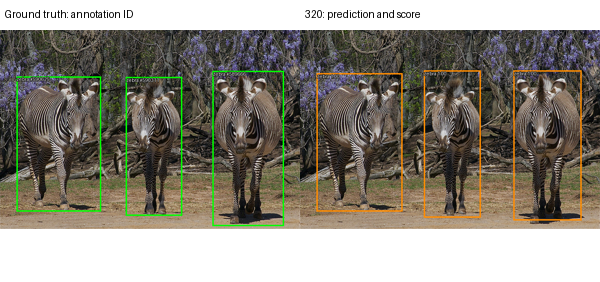

In [8]:
# 1-2 실습 코드
# 도움말 · 정답 행은 xmin으로, 예측은 점수로 정렬됩니다. 화면의 왼쪽과 예측 1위가 같은지 확인하세요.
# 여기에 풀이를 작성하세요.
log, truth = validation_at(BEFORE)
# 320 입력으로 Validation 14장을 평가한 결과 (처음 한 번만 계산하고 val_cache에 저장해 재사용함)
# log = 예측 한 개당 한 행인 표, truth = 정답 객체 한 개당 한 행인 표
actual = zebras[["annotation_id","class_name","xmin","ymin","xmax","ymax"]].sort_values("xmin")
# zebras = 11760번 사진의 얼룩말 정답 3마리 표 (공통 준비 셀에서 만듦)
# 필요한 열만 고른 뒤 xmin(박스 왼쪽 경계)이 작은 순 = 화면 왼쪽 → 오른쪽 순으로 정렬함
kept = log[(log.image_id==11760) & (log.score>=SCORE)]
# 11760번 사진의 예측 중 신뢰도가 SCORE(0.50) 이상인 것만 남김
# & = 두 조건이 모두 True인 행만 고름 (조건마다 괄호로 감싸야 함)
display(actual.merge(kept[["hit_id","rank","score","box_iou","reason"]],   # 정답 표 오른쪽에 예측 정보를 붙임
                     left_on="annotation_id",right_on="hit_id",how="left").round(4))
# 정답의 annotation_id와 예측의 hit_id(짝을 맺은 정답 번호)가 같은 행끼리 연결함
# how="left": 정답 3행을 모두 남김 → 짝이 없는 정답은 예측 칸이 NaN(= 미검출)으로 나옴
# → 왼쪽 590625는 2위, 가운데 590311은 3위, 오른쪽 589666은 1위 예측과 연결 (모두 TP)
panel(draw_scene(11760,BEFORE),["Ground truth: annotation ID","320: prediction and score"])
# draw_scene → (정답 박스·주석 번호를 그린 사진, 320 입력 예측 중 점수 0.50 이상을 그린 사진)
# panel: 두 사진을 제목과 함께 가로로 나란히 표시함

#### 1-2 정답 및 해설

**정답**　왼쪽은 주석 590625·예측 2위, 중앙은 590311·3위, 오른쪽은 589666·1위입니다. 320 입력에서 세 마리가 모두 TP입니다. 오른쪽 얼룩말의 점수는 약 0.9991, 정답 박스와의 IoU는 약 0.9148입니다.

`sort_values("xmin")`은 화면의 왼쪽 경계가 작은 순서로 정답을 놓습니다. `rank`는 모델이 낸 전체 후보에서 점수가 높은 순위입니다. 같은 종이 세 번 나와도 객체 번호가 다르므로 이름 zebra만으로 행을 연결할 수 없습니다. `audit_one`은 점수 순서대로 같은 클래스의 미사용 정답 중 가장 잘 겹치는 후보를 찾아 IoU가 0.50 이상일 때 한 쌍을 확정합니다.

가령 같은 오른쪽 얼룩말 위에 다른 zebra 후보가 추가되고 남은 정답과 충분히 겹치지 않는다면, 기존 정답을 다시 세지 않습니다. 이 추가 후보는 중복 FP입니다. 이는 판정법 설명을 위한 경우이고, 이 사진의 실제 320 결과에서는 그 중복이 관찰되지 않았습니다.

### 1-3. 예측 표의 FP와 정답 표의 FN 분리해서 세기

320 Validation에서 점수 0.50 이상 후보를 판정 이유별로 세고, 정답 표에서 미검출을 뽑으세요. Precision·Recall을 손으로 검산하고 가장 먼저 살펴볼 사진 하나를 고르세요.

In [9]:
# 1-3 실습 코드
# 도움말 · 분류가 잘못된 예측은 FP입니다. 올바른 후보가 또 없다면 같은 장면에 찾지 못한 정답도 남습니다.
# 여기에 풀이를 작성하세요.
log, truth = validation_at(BEFORE)            # 320 입력의 Validation 결과 (log: 예측 표, truth: 정답 표)
kept = log.loc[log.score>=SCORE]              # 신뢰도 0.50 이상인 예측만 남김 → 최종 예측 17개
types = ["TP","클래스 오류","중복","위치 오류","기타 오검출"]   # audit_one이 예측마다 붙이는 판정 이유 5가지
display(kept.reason.value_counts().reindex(types,fill_value=0).to_frame("예측 건수"))
# value_counts: 이유별 개수를 셈
# reindex(types, fill_value=0): types 순서로 줄을 세우고, 한 번도 안 나온 이유는 0으로 채움
# to_frame: 결과를 "예측 건수" 열 하나짜리 표로 바꿈 → TP 16, 클래스 오류 1, 나머지 0
display(kept[kept.reason!="TP"][["image_id","name","score","reason","box_iou"]].round(4))
# FP 목록: 판정이 TP가 아닌 예측 = 모델이 내놓았지만 정답과 짝을 못 맺은 후보
# box_iou = 관심 정답 박스와 가장 많이 겹친 정도
display(truth.loc[~truth.found,["image_id","annotation_id","name","area_fraction"]].round(4))
# FN 목록: found가 False인 정답 = 모델이 찾지 못한 객체 (~ = True/False를 뒤집음)
# area_fraction = 정답 마스크 면적 ÷ 사진 전체 면적
tp = int(truth.found.sum())                   # True는 1로 세어짐 → 찾은 정답 수 = TP 16
print("TP/FP/FN",tp,len(kept)-tp,len(truth)-tp,"P/R",tp/len(kept),tp/len(truth))
# FP = 남긴 예측 수(17) − TP, FN = 정답 수(19) − TP
# Precision = TP ÷ 남긴 예측 수 = 16/17 ≈ 0.941, Recall = TP ÷ 정답 수 = 16/19 ≈ 0.842

,예측 건수
reason,
TP,16
클래스 오류,1
중복,0
위치 오류,0
기타 오검출,0


,image_id,name,score,reason,box_iou
18,117908,dog,0.9445,클래스 오류,0.8268


,image_id,annotation_id,name,area_fraction
14,117908,47200,cat,0.0863
15,171611,1806,dog,0.0013
17,61108,12582,dog,0.0286


TP/FP/FN 16 1 3 P/R 0.9411764705882353 0.8421052631578947


#### 1-3 정답 및 해설

**답**　14장의 관심 객체 정답은 19개이고 점수 문턱을 통과한 후보는 17개입니다. 정답과 연결된 후보 16개, 클래스 오류 후보 1개, 미검출 정답 3개입니다. Precision은 16/(16+1) = **94.12%**, Recall은 16/(16+3) = **84.21%**입니다.

`kept[kept.reason!="TP"]`가 돌려주는 한 행은 모델이 실제로 내놓은 후보입니다. 반면 `truth.loc[~truth.found]`는 정답 중 연결되지 않은 행을 돌려줍니다. 검출 후보가 하나도 없는 대상은 두 번째 표에서만 드러납니다. 두 표를 단순히 합쳐 서로 다른 네 개의 물체를 틀렸다고 해석하면 안 됩니다. 예를 들어 고양이 자리에 개를 낸 경우 잘못 낸 후보는 FP, 찾지 못한 고양이는 FN이 될 수 있습니다.

오류 이유는 수업용으로 한 후보당 하나만 기록합니다. 먼저 같은 클래스의 유효한 연결을 확인하고, 실패하면 중복, 다른 관심 클래스와 충분히 겹침, 같은 클래스와 일부만 겹침, 기타 순서로 확인합니다. 오류 행의 `box_iou`는 관심 정답과의 최대 겹침입니다. 클래스 오류에서는 박스가 잘 맞아도 이름이 달라 FP일 수 있습니다. 예를 들어 아래 크기 분석으로 이어갈 때는 61108번 사진의 누락된 개부터 살펴볼 수 있습니다.

**실제 한 행을 끝까지 읽기**　117908번 사진에서 모델은 dog 후보에 0.9445라는 높은 점수를 줬습니다. 관심 정답과의 박스 IoU가 0.8268이라 위치는 충분히 겹쳤지만, 해당 정답 47200의 종은 cat입니다. 이 dog 후보는 클래스 오류 FP 1건이고, 문턱을 통과한 올바른 cat 후보가 없어 고양이는 FN으로 기록됩니다. 높은 점수가 어떤 종류의 오류를 숨길 수 있는지 확인할 수 있는 예입니다.

### 1-4. 작은 객체에서 미검출이 많은지 분모까지 비교하기

정답 마스크 면적이 사진의 5% 미만인 집단과 그 밖의 집단에서 정답 수·미검출 수·미검출률을 비교하세요. 관측에서 나온 가설과 추가로 확인할 장면 조건을 구분하세요.

In [10]:
# 1-4 실습 코드
# 도움말 · 같은 “2건”이라도 정답 4개에서 나온 것과 15개에서 나온 것은 다릅니다.
# 여기에 풀이를 작성하세요.
_, objects_320 = validation_at(BEFORE)        # 320 입력 결과 중 정답 표(truth)만 받음 (_ = 쓰지 않는 값)
by_size = objects_320.assign(group=np.where(objects_320.area_fraction<0.05,"5% 미만","5% 이상"))
# np.where(조건, 참일 때 값, 거짓일 때 값): 면적 비율이 0.05 미만이면 "5% 미만", 아니면 "5% 이상"
# assign: 그 결과를 group이라는 새 열로 붙인 복사본을 만듦 (원본 표는 그대로)
stats = by_size.groupby("group").found.agg(total="size",detected="sum")
# group 값이 같은 행끼리 묶어 found 열을 요약함
# total = 행 수(정답 개수), detected = True 개수(찾은 정답 수)
stats["missed"] = stats.total-stats.detected  # 놓친 수 = 정답 수 − 찾은 수
stats["miss_rate"] = stats.missed/stats.total # 미검출률 = 놓친 수 ÷ 그 집단의 정답 수 (분모를 집단별로 둠)
display(stats.round(4))                       # → 5% 미만 2/4 = 0.5, 5% 이상 1/15 ≈ 0.0667

,total,detected,missed,miss_rate
group,,,,
5% 미만,4,2,2,0.5000
5% 이상,15,14,1,0.0667


#### 1-4 정답 및 해설

**답**　5% 미만에서는 정답 4개 중 2개를 놓쳐 미검출률이 **50%**입니다. 5% 이상에서는 정답 15개 중 1개를 놓쳐 **6.67%**입니다. 두 집단을 합치면 정답 19개, 미검출 3개로 앞 문항과 일치합니다.

`area_fraction`은 해당 객체의 정답 마스크 전경 수를 원본 사진의 가로×세로로 나눈 비율입니다. 0.05는 이 수업에서 정한 경계이며 COCO의 공식 small 객체 기준과는 다릅니다. `size`는 정답 행 수를, `sum`은 True인 found의 수를 셉니다. 미검출률의 분모를 전체 19개로 놓으면 집단 간 난이도를 비교할 수 없습니다.

이 결과에서 “320으로 축소할 때 작은 몸의 구별 단서가 줄어들었을 수 있다”는 가설을 세울 수 있습니다. 작은 집단에서는 객체 하나가 25%p를 움직이고, 가림·조명·배경 복잡도도 함께 달라질 수 있습니다. 다음 절에서는 같은 사진·가중치·판정 기준을 유지하고 입력 크기만 바꿔 이 가설을 확인합니다.

## 필수 2 · 전처리의 유효성을 검사하고 오류 원인에 맞는 변경 실험하기

### 2-1. 같은 반쪽 사진이어도 원래 객체 라벨을 유지할 수 있을까?

주석 589666의 사진·마스크에 같은 왼쪽 또는 오른쪽 절반 자르기를 적용하세요. 남은 픽셀 수·보존율·새 마스크 박스를 구하고, 어느 창에서 해당 주석을 학습 예제로 유지할지 쓰세요.

원본 (425, 640) 대상 픽셀 30338 보존율 100.0% 박스 (454, 88, 606, 418)


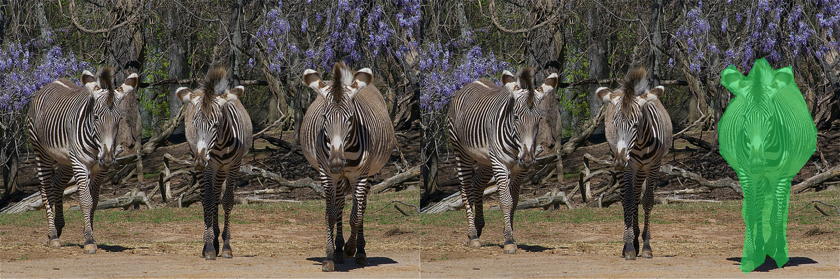

왼쪽 (425, 320) 대상 픽셀 0 보존율 0.0% 박스 None


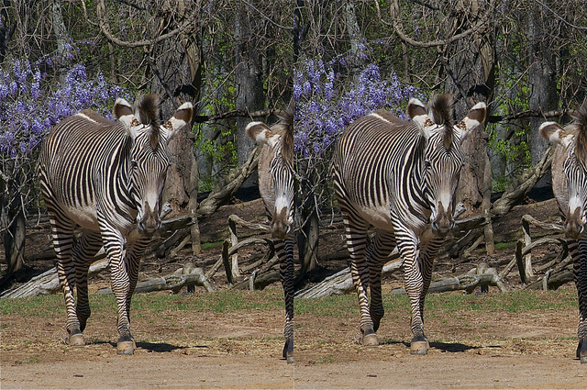

오른쪽 (425, 320) 대상 픽셀 30338 보존율 100.0% 박스 (134, 88, 286, 418)


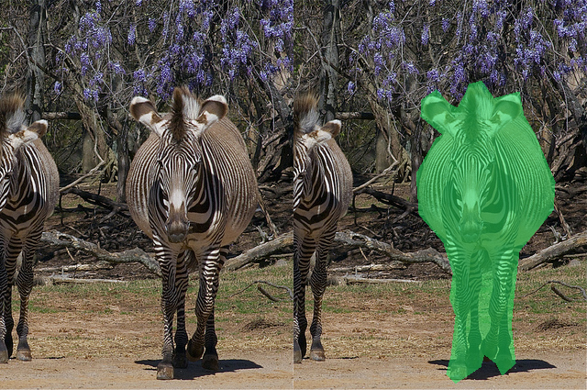

In [11]:
# 2-1 실습 코드
# 도움말 · mask_box는 전경 픽셀을 감싸는 정수 XYXY를 반환합니다. 오른쪽·아래 끝은 포함하지 않으며, 전경이 없으면 None입니다.
# 여기에 풀이를 작성하세요.
mid = zebra_photo.shape[1]//2                 # shape = (세로, 가로, 채널) → shape[1] = 가로 640 → 가운데 320
original_n = int(zebra_mask.sum())            # 원본 마스크의 True(얼룩말 589666) 픽셀 수 → 30338
for label,col in [("원본",slice(None)),("왼쪽",slice(None,mid)),("오른쪽",slice(mid,None))]:
    # slice(None) = [:] 전체, slice(None,mid) = [:320] 열 0~319, slice(mid,None) = [320:] 열 320~639
    photo, mask = zebra_photo[:,col], zebra_mask[:,col]
    # 사진과 마스크를 같은 열 범위로 자름 (행은 전부 유지) → 둘이 계속 같은 위치를 가리킴
    assert photo.shape[:2] == mask.shape      # 사진의 (세로, 가로)와 마스크 크기가 같은지 확인 (다르면 오류로 멈춤)
    print(label,mask.shape,"대상 픽셀",mask.sum(),"보존율",f"{mask.sum()/original_n:.1%}","박스",mask_box(mask))
    # 보존율 = 잘린 창에 남은 픽셀 ÷ 원본 픽셀 (:.1% → 소수 첫째 자리까지 퍼센트로 표시)
    # mask_box: 남은 True 픽셀을 감싸는 박스 (xmin, ymin, xmax, ymax), 하나도 없으면 None
    # → 원본 (454, 88, 606, 418) / 왼쪽 0픽셀·None / 오른쪽 30338픽셀·(134, 88, 286, 418)
    # 오른쪽 창은 원본 x=320이 새 원점(0)이므로 x 좌표가 320씩 줄어듦, y는 그대로
    show_pair(photo,mask)                     # 왼쪽: 잘린 사진, 오른쪽: 마스크 영역을 초록색으로 덧칠한 사진

#### 2-1 정답 및 해설

**답**　원본 30,338픽셀 중 왼쪽 절반에 남은 것은 0픽셀, 오른쪽 절반에 남은 것은 30,338픽셀입니다. 589666의 개체 라벨을 유지할 수 있는 쪽은 오른쪽입니다.

`shape[1]`은 가로 640이므로 `mid`는 320입니다. `[:, :320]`은 모든 행에서 열 0~319를, `[:, 320:]`은 열 320~639를 남깁니다. 오른쪽 얼룩말 마스크의 원본 정수 박스는 (454, 88, 606, 418)입니다. 오른쪽 창의 새 원점은 원본 x=320이므로 새 박스는 (134, 88, 286, 418)입니다. y는 자르지 않아 그대로입니다. 이 좌표는 마스크에서 다시 계산한 정수 경계이며 COCO 표의 소수 박스와 계산 방법이 다릅니다.

왼쪽 사진에도 다른 얼룩말이 보입니다. 사진 단위로 “얼룩말이 있다”는 답은 가능하지만, 원본 오른쪽 개체의 박스·마스크를 왼쪽 창에 그대로 붙이면 가르치는 대상이 달라집니다. 객체 탐지 학습용으로 왼쪽 창을 보존한다면 그 창에 실제로 남은 **다른 개체들**의 주석을 각각 변환해야 합니다. 이 문항의 픽셀 검사는 지정한 개체 하나에 대한 것입니다.

### 2-2. 픽셀 수가 보존돼도 라벨이 틀릴 수 있는가?

얼룩말 사진을 좌우 반전하세요. 마스크도 반전한 경우와 원래 마스크를 잘못 붙인 경우를 나란히 표시하세요. 면적·마스크 박스·올바른 마스크와 잘못 붙인 마스크의 IoU를 구하고 검수 기준을 제안하세요.

올바른/기존 마스크 면적 30338 30338
올바른/기존 마스크 박스 (34, 88, 186, 418) (454, 88, 606, 418)
교집합/합집합/IoU 0 60676 0.0


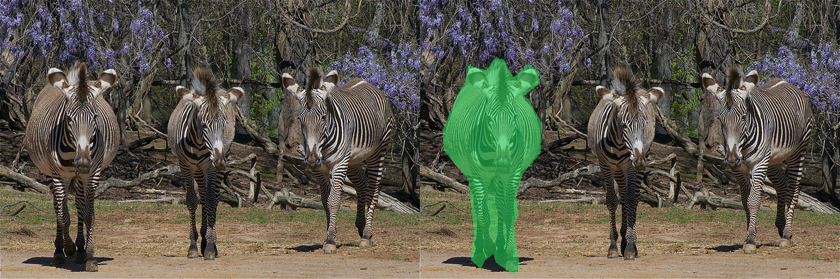

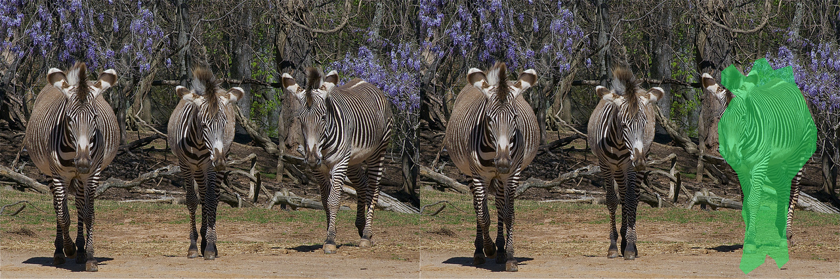

In [12]:
# 2-2 실습 코드
# 도움말 · 색상 배열은 (행, 열, 채널), 마스크는 (행, 열)입니다. 두 배열 모두 열 축의 순서를 바꿉니다.
# 여기에 풀이를 작성하세요.
flipped_photo = np.flip(zebra_photo,axis=1).copy()
# np.flip(..., axis=1): 1번 축(열 = 가로)의 순서를 뒤집음 → 좌우 반전
# .copy(): 뒤집어 보이기만 하는 '보기'가 아니라 새 배열로 만듦
correct_mask = np.flip(zebra_mask,axis=1).copy()   # 올바른 방법: 마스크도 사진과 똑같이 좌우 반전함
stale_mask = zebra_mask                       # 잘못된 방법: 반전 전 마스크를 그대로 붙임
overlap = np.count_nonzero(correct_mask & stale_mask)   # 교집합: 두 마스크 모두 True인 픽셀 수 (& = 그리고)
combined = np.count_nonzero(correct_mask | stale_mask)  # 합집합: 둘 중 하나라도 True인 픽셀 수 (| = 또는)
print("올바른/기존 마스크 면적",correct_mask.sum(),stale_mask.sum())
# → 둘 다 30338 → 면적(픽셀 수)만 봐서는 잘못 붙인 라벨을 잡을 수 없음
print("올바른/기존 마스크 박스",mask_box(correct_mask),mask_box(stale_mask))
# → (34, 88, 186, 418) vs (454, 88, 606, 418): 반전하면 x 범위 [a, b)가 [640−b, 640−a)로 바뀌고 y는 그대로
print("교집합/합집합/IoU",overlap,combined,overlap/combined)
# IoU = 교집합 ÷ 합집합 → 0, 60676, 0.0 (두 마스크가 전혀 겹치지 않음)
show_pair(flipped_photo,correct_mask)         # 초록색이 반전된 얼룩말 몸 위에 칠해짐 (정상)
show_pair(flipped_photo,stale_mask)           # 초록색이 얼룩말이 옮겨 간 자리가 아닌 원래 자리에 칠해짐 (라벨 오류)

#### 2-2 정답 및 해설

**답**　두 마스크의 전경 수는 모두 30,338픽셀입니다. 그런데 정확히 반전한 마스크의 박스는 (34, 88, 186, 418)이고 원래 마스크의 박스는 (454, 88, 606, 418)입니다. 둘이 겹치는 픽셀은 0이어서 합집합 60,676픽셀, IoU 0입니다.

가로 640인 사진에서 원본 픽셀의 x를 새 x로 바꾸는 식은 639−x입니다. 끝을 포함하지 않는 박스 [454,606)은 반전 후 [640−606,640−454) = [34,186)이 됩니다. `axis=1`은 열 순서를 뒤집습니다. 이미지와 마스크에 같은 연산을 하면 동물 몸과 초록색 강조 영역이 함께 이동합니다.

잘못 붙인 경우에도 면적 합계와 배열 크기 검사는 모두 통과합니다. 따라서 학습용 증강을 검수할 때는 ① 이미지·마스크 모양 일치 ② 남은 대상 픽셀 수 ③ 변환된 마스크와 객체의 위치가 일치하는지까지 확인해야 합니다. 두 그림에서 고른 개체가 어디에 칠해졌는지를 마지막 근거로 삼을 수 있습니다.

### 2-3. 입력을 키운 뒤 새로 찾은 객체와 놓치게 된 객체 추적하기

같은 모델로 Validation의 입력 짧은 변을 640으로 바꾸세요. 320·640의 정답 표를 객체 ID로 결합해 회복·악화·계속 검출·계속 미검출을 각각 세세요. 회복 사례와 악화 사례를 한 장씩 골라 실제 예측 그림을 비교하세요.

,정답 객체 수
change,
계속 검출,15
회복,2
악화,1
계속 미검출,1


,image_id,annotation_id,name,320,640,change
17,61108,12582,dog,False,True,회복
14,117908,47200,cat,False,True,회복
12,174231,50142,cat,True,False,악화


회복 사진 61108 주석 12582 dog


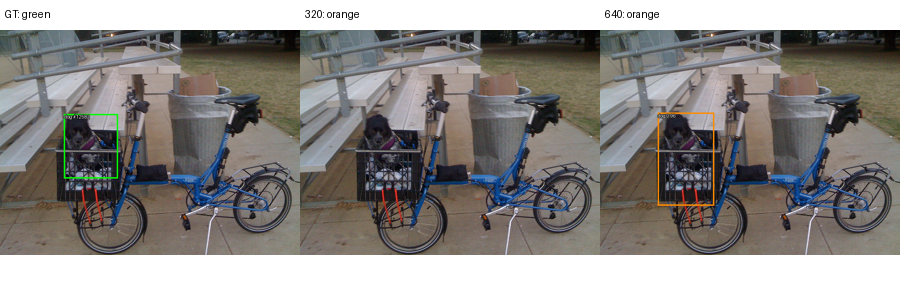

악화 사진 174231 주석 50142 cat


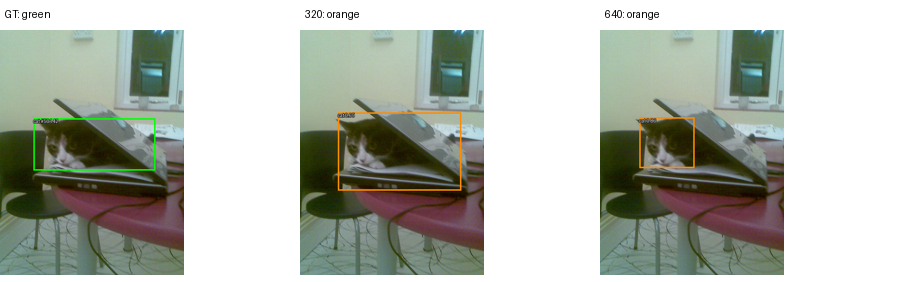

In [13]:
# 2-3 실습 코드
# 도움말 · paired_objects는 (image_id, annotation_id, name)으로 두 정답 표를 결합합니다. 두 found 열을 비교하세요.
# 여기에 풀이를 작성하세요.
pairs = paired_objects()
# 320·640 두 정답 표를 (image_id, annotation_id, name)으로 이어 붙인 표 (정답 객체 19행)
# 열 320 = 320 입력에서 찾았는지, 열 640 = 640 입력에서 찾았는지 (True/False)
pairs["change"] = np.select(
    [pairs[BEFORE] & pairs[AFTER], ~pairs[BEFORE] & pairs[AFTER], pairs[BEFORE] & ~pairs[AFTER]],
    ["계속 검출","회복","악화"],default="계속 미검출")
# np.select(조건 목록, 값 목록, default): 행마다 처음으로 True가 되는 조건의 값을 넣음
# 둘 다 찾음 → 계속 검출 / 320 못 찾고 640 찾음 → 회복 / 320 찾고 640 못 찾음 → 악화
# 어느 조건에도 안 맞으면(둘 다 못 찾음) → default "계속 미검출"  (~ = 뒤집기, & = 그리고)
display(pairs.change.value_counts().to_frame("정답 객체 수"))
# 네 범주의 개수 → 15, 2, 1, 1 (합 19 = 전체 정답 수, 빠진 객체가 없다는 확인)
display(pairs.loc[pairs[BEFORE]!=pairs[AFTER]].sort_values("annotation_id"))
# 두 설정에서 판정이 달라진 정답(회복·악화)만 주석 번호 순으로 표시
for category in ["회복","악화"]:              # 회복 사례 한 장, 악화 사례 한 장을 그림으로 비교
    changed = pairs.loc[pairs.change==category].sort_values("annotation_id")
    if changed.empty:                         # 해당 범주의 사례가 없으면
        print(category,"사례 없음")
        continue                              # 메시지만 출력하고 다음 범주로 넘어감
    example = changed.iloc[0]                 # 주석 번호가 가장 작은 사례 한 행
    key = int(example.image_id)               # 그 객체가 들어 있는 사진 ID
    print(category,"사진",key,"주석",int(example.annotation_id),example["name"])
    # example["name"]: name 열 값 (example.name은 행 이름(인덱스)을 뜻하므로 대괄호로 꺼냄)
    gt_view, old_view = draw_scene(key,BEFORE)   # 정답 그림, 320 입력 예측 그림
    _, new_view = draw_scene(key,AFTER)          # 640 입력 예측 그림 (정답 그림은 같으므로 _로 버림)
    panel([gt_view,old_view,new_view],["GT: green","320: orange","640: orange"])
    # 정답(초록)·320 예측(주황)·640 예측(주황) 세 장을 나란히 표시함

#### 2-3 정답 및 해설

**답**　계속 찾은 객체 15개, 새로 찾은 객체 2개, 이전엔 찾았으나 놓치게 된 객체 1개, 계속 놓친 객체 1개입니다. 네 칸의 합이 19여야 정답 표에서 빠진 객체가 없다는 것을 확인할 수 있습니다.

| 사진 / 주석 ID | 실제 클래스 | 320 → 640 | 판단 |
|---|---|---|---|
| 61108 / 12582 | dog | False → True | 원본 면적의 약 2.86%인 개가 새로 정답과 연결됩니다. |
| 117908 / 47200 | cat | False → True | 고양이 한 마리를 더 찾았습니다. |
| 174231 / 50142 | cat | True → False | 입력을 키웠을 때 검출 기준을 통과하지 못하게 된 고양이입니다. |

`validate="one_to_one"`는 한 객체가 같은 표 안에서 여러 행으로 불어나지 않도록 결합을 확인합니다. `~`는 참·거짓을 뒤집고 `&`는 양쪽 조건이 모두 참인 행을 고릅니다. 예를 들어 `~pairs[320] & pairs[640]`이 회복입니다. 검출 수는 16에서 17로 1개 늘었지만 실제 판정이 바뀐 정답은 3개입니다. **2개 회복 − 1개 악화 = 순증 1개**입니다.

그림의 초록 박스는 정답, 주황 박스는 점수 0.50을 넘긴 예측입니다. 주황 박스가 보이더라도 클래스나 IoU가 기준을 만족해야 검출 성공입니다. 사진 전체에 있는 모든 물체에 대해 “보였다/사라졌다”라고 읽지 말고, 표에서 고른 주석 번호의 객체를 찾아 위치와 이름을 확인하세요.

**세 객체에서 판정을 바꾼 조건 추적**　동일 사진을 두 설정으로 다시 추론한 결과입니다. 성공한 경우 실제 매칭된 후보를, 실패한 경우 모델 내부에 남은 같은 종 후보 중 해당 정답과 가장 많이 겹친 후보를 읽었습니다. 빈칸은 내부 출력 범위에 같은 종 후보가 없었다는 뜻입니다.

| 주석 | 짧은 변 | 정답 종 후보 점수 | 그 후보의 박스 IoU | 검출 성공 |
|---|---:|---:|---:|---|
| 12582 | 320 | — | — | 아니오 |
| 12582 | 640 | 0.9571 | 0.5909 | 예 |
| 47200 | 320 | 0.4762 | 0.8759 | 아니오 |
| 47200 | 640 | 0.9856 | 0.7458 | 예 |
| 50142 | 320 | 0.6500 | 0.6173 | 예 |
| 50142 | 640 | 0.4348 | 0.6509 | 아니오 |

50142번 고양이를 보면 640에서 박스 IoU는 **0.6173 → 0.6509**로 오히려 높아졌습니다. 하지만 cat 점수가 **0.6500 → 0.4348**로 떨어져 0.50 문턱을 넘지 못했습니다. 이 사례의 악화를 단순히 위치 오류로 적으면 원인을 잘못 짚습니다. 반대로 47200번 고양이는 320에서도 잘 겹치는 cat 후보가 있었지만 점수 0.4762가 문턱에 못 미쳤고, 640에서 점수 0.9856으로 정답 처리됐습니다.

### 2-4. 작은 물체와 어두운 장면에는 어떤 후속 실험이 맞을까?

두 입력 크기의 작은 객체 집계로 해상도 가설을 평가하세요. 어두운 사진에서 오류가 반복될 때의 증강 실험, Feature Extraction에서 Fine-tuning으로 전환하는 실험을 각각 제안하세요. 무엇을 고정하고 무엇을 검증할지도 쓰세요.

In [14]:
# 2-4 실습 코드
# 도움말 · 입력 크기·밝기·학습 범위를 동시에 바꾸면 결과를 어느 변경에 돌릴지 판단하기 어렵습니다.
# 여기에 풀이를 작성하세요.
for size in (BEFORE,AFTER):                   # 짧은 변 320, 640을 차례로
    _, t = validation_at(size)                # 그 크기의 정답 표(truth)만 받음
    group = np.where(t.area_fraction < 0.05,"5% 미만","5% 이상")   # 정답마다 크기 집단 이름 (1-4와 같은 5% 기준)
    print("짧은 변",size)
    display(t.groupby(group).found.agg(["sum","size","mean"]).rename(
        columns={"sum":"검출","size":"정답","mean":"Recall"}).round(4))
    # groupby(group): 열 이름 대신 같은 길이의 배열로도 묶을 수 있음
    # found의 sum = 찾은 수, size = 정답 수, mean = True 비율 = Recall
    # rename: 열 이름을 한글로 바꿔 표시함
    # → 5% 미만 Recall 0.50 → 0.75 (1개 더 찾음), 5% 이상 0.9333 → 0.9333 (변화 없음)

짧은 변 320


,검출,정답,Recall
5% 미만,2,4,0.5000
5% 이상,14,15,0.9333


짧은 변 640


,검출,정답,Recall
5% 미만,3,4,0.7500
5% 이상,14,15,0.9333


#### 2-4 정답 및 해설

**예시 답안**　5% 미만 객체에서는 2/4 → 3/4로 한 개를 더 찾았습니다. 5% 이상에서는 14/15 → 14/15로 정답 수가 같습니다. 큰 집단 안에서는 한 고양이가 회복하고 다른 고양이가 악화돼 합계에서 상쇄됐습니다. 따라서 해상도 변경은 이 표본의 작은 객체 미검출을 줄이는 데 도움이 됐지만, 어떤 크기의 객체든 반드시 좋아진다고 할 수는 없습니다.

**어두운 장면을 의심할 때**　먼저 밝은 장면과 어두운 장면을 나누고 각 집단의 실제 정답 수와 FN을 함께 셉니다. 어두운 사진이 단순히 많았다면 오류 건수만 많을 수도 있습니다. 밝기 범위를 사전에 정해 Train 이미지에만 밝기 변환을 적용한 실험을 설계합니다. 같은 원본의 좌표와 마스크는 유지하되 너무 어두워 사람이 대상을 알아보기 어려워진 변환은 검수합니다. Validation의 같은 어두운 사진을 원래 밝기 그대로 평가해 오류율을 비교합니다. 이번 노트북에서 실제 측정한 변경은 해상도이고, 밝기 증강은 다음 실험 제안입니다.

**학습 범위를 바꿀 때**　특징 추출기를 고정한 채 출력층만 학습하면 작은 데이터로 계산을 줄일 수 있습니다. 새 환경의 윤곽·재질에 기존 특징이 맞지 않는다는 근거가 있으면 마지막 특징 블록도 풀어 더 작은 학습률로 미세조정할 수 있습니다. 원본 분할과 전처리·평가 문턱을 맞춘 상태에서 Train만 좋아지고 Validation 미검출이 늘면 확대 학습을 채택할 근거가 부족합니다. 두 실험을 분리해야 어느 변경이 결과에 영향을 줬는지 추적할 수 있습니다.

## 과제 1 · 새로운 이미지의 라벨을 검수하고 개선안을 결정하기

### 3-1. 같은 300열에 고양이가 얼마나 남는가?

사진 22892, 주석 46699의 원본·왼쪽 300열·오른쪽 300열을 비교하세요. 원본 대비 개체 픽셀 보존율과 새 마스크 박스를 계산하고, 고양이 전체 형태를 보존하는 학습 예제로 어느 창을 선택할지 근거를 쓰세요.

In [ ]:
# 3-1 실습 코드
# 도움말 · 두 창 모두 같은 폭입니다. 각 창의 전경 수를 원본 고양이 전경 수로 나누세요.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 코드 출력 또는 그림에서 확인한 근거
- 이 근거로 내릴 수 있는 판단

### 3-2. 검출 수·오류 종류·지표의 변화를 한 표로 비교하기

동일한 Validation에서 After − Before를 계산하세요. TP·FP·FN은 건, Precision·Recall·mAP50·매칭 마스크 IoU는 0~1 값을 100배 한 척도의 점수 차로 표시하세요. FP 총수와 FP 유형이 함께 어떻게 바뀌었는지 근거를 쓰세요.

In [ ]:
# 3-2 실습 코드
# 도움말 · summary의 mAP50은 후보 순위를 사용합니다. 고정 문턱 Precision 한 점과 구분하세요.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 코드 출력 또는 그림에서 확인한 근거
- 이 근거로 내릴 수 있는 판단

### 3-3. Validation에서 결정한 설정을 잠근 뒤 Test 확인하기

사전에 제시한 규칙으로 입력 크기를 선택한 후 Test에 기준 설정과 선택 설정을 적용하세요. 두 설정이 같으면 한 번만 실행하세요. Test의 미검출 감소와 추가 오검출을 함께 보고하고 Validation에서 본 변화와 비교하세요.

In [ ]:
# 3-3 실습 코드
# 도움말 · 변경 설정은 Recall이 더 높고 Precision 하락이 5%p 이내여야 합니다. test_ids는 결정 이후에 사용하세요.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 코드 출력 또는 그림에서 확인한 근거
- 이 근거로 내릴 수 있는 판단

### 3-4. 제조 사례와 실제 COCO 결과로 서로 다른 결론 쓰기

교안 제조 사례의 지표·오류 건수 변화량을 구해 COCO 실측과 구분하세요. 서로 다른 Validation 사진 200장에서 mAP50 0.75와 0.82가 나온 두 모델의 우열을 판단할 수 있는지, 공정한 재평가 조건과 함께 답하세요.

In [ ]:
metrics = pd.DataFrame({"Metric":["Precision","Recall","mAP@0.5"],
                        "Before":[0.85,0.60,0.68], "After":[0.78,0.78,0.74]})
cases = pd.DataFrame({"유형":["작은 균열 미검출","잘못된 균열 검출","위치 오류"],
                      "Before":[20,5,7], "After":[8,9,4]})

# 3-4 실습 코드
# 도움말 · 제조 사례 원자료는 아래 제공됩니다. 단위가 다른 두 표를 분리해서 계산하세요.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 코드 출력 또는 그림에서 확인한 근거
- 이 근거로 내릴 수 있는 판단

## 실습 마무리

### 실습 마무리 · 예시 답안

**1. 진단**　640으로 바꾸자 작은 개 12582는 회복됐지만 고양이 50142는 오히려 놓쳤습니다. 입력 크기 실험과 별개로, 학습 예제를 자를 때 46699번 고양이의 왼쪽 300열에는 전경이 9.21%만 남았습니다. 원래 전체 고양이 라벨을 그대로 쓰면 입력과 정답이 어긋날 수 있습니다.

**2. 조치**　자르기에서는 창 폭을 고정하고 위치만 바꿨으며 사진과 마스크에 같은 슬라이스를 적용했습니다. 검출 실험에서는 COCO Train 12장으로 출력층을 한 번 학습하고, 그 뒤 같은 가중치에 대해 추론 해상도만 변경했습니다. 원본 사진, 정답 객체, 클래스 목록, 점수·IoU 문턱을 고정했습니다.

**3. 결론**　Validation에서 2개가 회복되고 1개가 악화돼 미검출을 줄인 순효과는 1개였습니다. 규칙에 따라 640을 선택한 후 Test에서 놓친 동물은 6개에서 3개로 줄었지만, 잘못 남긴 후보는 3개에서 5개로 늘었습니다. 이 결과는 동물이 포함된 소표본에서의 관측입니다. 대상이 없는 장면이나 다른 조명·클래스에서도 오검출이 얼마나 발생할지는 이 구성만으로 확인할 수 없습니다.